Name

Labpartner(s)

In [1]:
#import statements go here
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats

# Class 12.1

# Warmups 12.1

Note: finish this for lab if you don't finish in class.

Log into the Supermike III LSU HPC using ssh (in the terminal). See the help docs we went over last time. 

**W.1.** Investigate each of the following basic unix/linux commands:
- ls
- pwd
- cd
- scp
- scp -r

What do each of these do? If you forgot, you can type "man ls", etc. to see the documentation.

**W.2** Look up the LSU HPC documentation for /work and /home, what is the difference? What are the quotas for each? How long will files last? Are they backed up?

# Lecture 12.1

### Agenda:


Some useful things to do with a timeseries
- datetime objects
- basic line fitting
- moving averages
- detrending

In [2]:
from datetime import datetime, timedelta
import pandas as pd

#### Defining a specfic date

In [3]:
date1 = datetime(1996,1,1) 

In [4]:
# this is a datetime object
date1

datetime.datetime(1996, 1, 1, 0, 0)

In [5]:
# print out the date
print(date1)

1996-01-01 00:00:00


In [6]:
# you can also format the date as a string however you like (useful for plots)
date1.strftime("%m/%d/%Y")

'01/01/1996'

In [7]:
# defining a date with hours, minutes and seconds
date2 = datetime(1996,1,1, 13, 34, 6) # note using 24 clock (miltary time) here

In [8]:
print(date2)

1996-01-01 13:34:06


In [9]:
#what is going to happen here?
date2.strftime("%m-%d-%Y")

'01-01-1996'

In [10]:
date1.today() #somehow it knows what timezone I am (probably from my computer)

datetime.datetime(2026, 11, 15, 13, 39, 28, 734739)

#### If we want to increment the date we can use timedelta

In [11]:
date1 = date1 + timedelta(days=1)
print(date1)

1996-01-02 00:00:00


In [12]:
date1 = date1 + timedelta(minutes = 2, seconds=1)
print(date1)

1996-01-02 00:02:01


In [13]:
# you can also do things like add fractional days
date1 = date1 + timedelta(days=1.5)
print(date1)

1996-01-03 12:02:01


We can find the time difference between two dates

In [14]:
timediff = date2-date1
timediff
print(timediff)

-2 days, 1:32:05


#### We can also define timeseries using pandas 

In [15]:
pd.date_range?

In [16]:
# note the default is daily
my_daterange = pd.date_range(start='1/1/2018', end='1/08/2018')

In [17]:
my_daterange

DatetimeIndex(['2018-01-01', '2018-01-02', '2018-01-03', '2018-01-04',
               '2018-01-05', '2018-01-06', '2018-01-07', '2018-01-08'],
              dtype='datetime64[us]', freq='D')

In [18]:
# this can be indexed like any array
my_daterange[-1]
# note the result is a timestamp, which is similar to a datetime object, but not exactly

Timestamp('2018-01-08 00:00:00')

In [19]:
print(my_daterange[1])

2018-01-02 00:00:00


In [20]:
# you can convert a datetime to a timestamp
pd.Timestamp(datetime(2012, 5, 1))

Timestamp('2012-05-01 00:00:00')

In [21]:
# we can also specfiy the frequency
my_daterange2 = pd.date_range(start='1/1/2018',end = '12/1/2021', freq='ME')
my_daterange2

DatetimeIndex(['2018-01-31', '2018-02-28', '2018-03-31', '2018-04-30',
               '2018-05-31', '2018-06-30', '2018-07-31', '2018-08-31',
               '2018-09-30', '2018-10-31', '2018-11-30', '2018-12-31',
               '2019-01-31', '2019-02-28', '2019-03-31', '2019-04-30',
               '2019-05-31', '2019-06-30', '2019-07-31', '2019-08-31',
               '2019-09-30', '2019-10-31', '2019-11-30', '2019-12-31',
               '2020-01-31', '2020-02-29', '2020-03-31', '2020-04-30',
               '2020-05-31', '2020-06-30', '2020-07-31', '2020-08-31',
               '2020-09-30', '2020-10-31', '2020-11-30', '2020-12-31',
               '2021-01-31', '2021-02-28', '2021-03-31', '2021-04-30',
               '2021-05-31', '2021-06-30', '2021-07-31', '2021-08-31',
               '2021-09-30', '2021-10-31', '2021-11-30'],
              dtype='datetime64[us]', freq='ME')

See the documentation for lots more functionality

### Working with timeseries data: global sea surface temperature (SST)

We are going to be using some data from the epa website here: https://www.epa.gov/climate-indicators/climate-change-indicators-sea-surface-temperature

This is globally averaged Extended Reconstructed Sea Surface Temperature (ERSST)v.4 from NOAA, which combines satilite, ship and other in situ (in place, i.e. in the water) data. If you follow the links on the above you can get the gridded (i.e. map) product in netcdf format for the latest product (v.5). We are just going to play around with the globally averaged data

In [22]:
sst= pd.read_csv('https://www.epa.gov/system/files/other-files/2024-06/sea-surface-temp_fig-1.csv')

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xb0 in position 247: invalid start byte

That didn't work. I did some googling to figure out why and added an encoding specification: 

In [23]:
sst= pd.read_csv('https://www.epa.gov/system/files/other-files/2024-06/sea-surface-temp_fig-1.csv',
                encoding = 'latin1')

In [24]:
sst

,"Figure 1. Average Global Sea Surface Temperature, 1880-2023",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,Source: EPA's Climate Change Indicators in the...,NaN,NaN,NaN
1,"Data source: NOAA, 2024",NaN,NaN,NaN
2,Web update: June 2024,NaN,NaN,NaN
3,Units: temperature anomaly (°F),NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
...,...,...,...,...
145,2019,0.878,0.822,0.935
146,2020,0.846,0.804,0.888
147,2021,0.668,0.622,0.714
148,2022,0.743,0.701,0.786


I want this to be indexed by year, I don't want the first column, and I want specify the header of all the metadata so it's doesn't mess up my analysis:

In [25]:
sst= pd.read_csv('https://www.epa.gov/sites/production/files/2016-08/sea-surface-temp_fig-1.csv',
                 index_col = 0, # this makes the year the index
                  header = 6,
                 #skiprows = [0,1,2,3,4,5], # this works too, need to skip all the comments
                 encoding ='latin1' # had to do this to get it to work, thanks stack exchange
                )

In [26]:
sst

,Annual anomaly,Lower 95% confidence interval,Upper 95% confidence interval
Year,,,
1880,-0.470009,-0.672646,-0.267371
1881,-0.356879,-0.560588,-0.153169
1882,-0.372661,-0.575728,-0.169594
1883,-0.448443,-0.650804,-0.246082
1884,-0.589754,-0.790478,-0.389030
...,...,...,...
2011,0.428674,0.133289,0.724058
2012,0.528696,0.232869,0.824523
2013,0.584674,0.289227,0.880122


<Axes: xlabel='Year'>

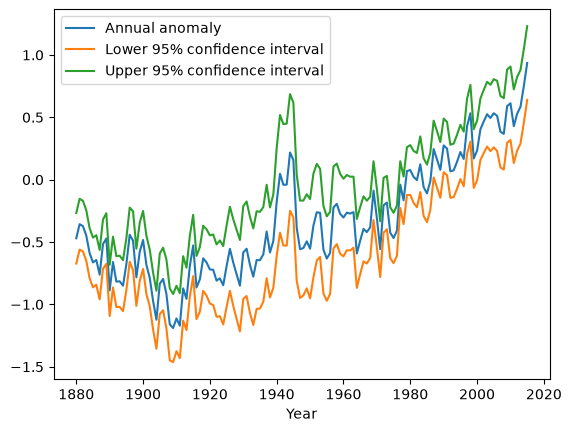

In [27]:
sst.plot()

I'm going to reset my universal plotting specs (I usually do this at the top with my import statements) to make the plot nice

In [28]:
#Set plotting formats
import matplotlib as mpl
mpl.rcParams['figure.figsize'] = [13.0, 6.0]
mpl.rcParams['font.size'] = 16
mpl.rcParams['legend.fontsize'] = 'medium'
mpl.rcParams['figure.titlesize'] = 'medium'
mpl.rcParams['lines.linewidth'] = 2.0

<Axes: xlabel='Year'>

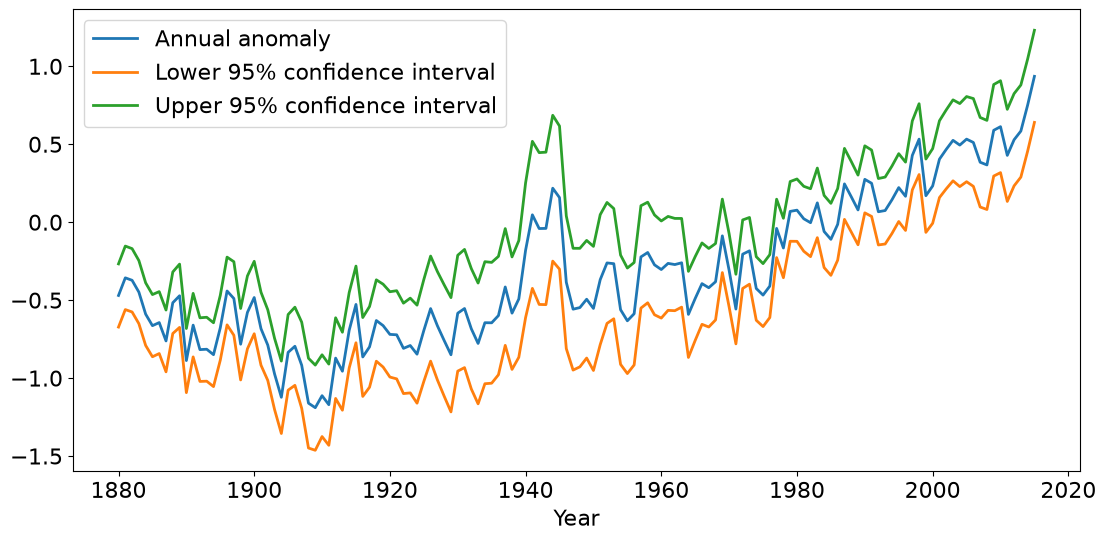

In [29]:
sst.plot()

1850 is usually considered the beginning of the industrial revolution, so before human affected climate by burning fossil fuels (but we did major land use changes and had impacts on many species' extinctions)

There is a definate trend in the data, with a big excursion in the 1940s

Let's ask some research questions. We will start these in lecture and you will finish them in lab:
- What is the trend in this data, that is how fast is SST increasing with time? 
- If we choose a different window for the trend analysis, how does this affect the answer?
- What causes all the interannual variablilty? If we detrend the data how does it look? Can we compare this with climate variabiltiy indices?
- What happened in the 1940s?

see: https://www.newscientist.com/article/dn11639-climate-myths-the-cooling-after-1940-shows-co2-does-not-cause-warming/

I am much more comfortable doing data analysis in xarray so I'm converting the pandas dataframe to an xarray dataset

In [30]:
import xarray as xr

In [31]:
sst_ds = sst.to_xarray()

In [32]:
sst_ds

<xarray.Dataset> Size: 4kB
Dimensions:                        (Year: 136)
Coordinates:
  * Year                           (Year) int64 1kB 1880 1881 1882 ... 2014 2015
Data variables:
    Annual anomaly                 (Year) float64 1kB -0.47 -0.3569 ... 0.9356
    Lower 95% confidence interval  (Year) float64 1kB -0.6726 -0.5606 ... 0.6401
    Upper 95% confidence interval  (Year) float64 1kB -0.2674 -0.1532 ... 1.231

If we want, we can add a pandas date range to this timeseries and use this for plotting. Not super needed here because it's annual, but would be useful if it was monthly or daily.

In [33]:
ssha_dates = pd.date_range(start = '1880', end = '2015', freq='YE')

In [34]:
ssha_dates

DatetimeIndex(['1880-12-31', '1881-12-31', '1882-12-31', '1883-12-31',
               '1884-12-31', '1885-12-31', '1886-12-31', '1887-12-31',
               '1888-12-31', '1889-12-31',
               ...
               '2005-12-31', '2006-12-31', '2007-12-31', '2008-12-31',
               '2009-12-31', '2010-12-31', '2011-12-31', '2012-12-31',
               '2013-12-31', '2014-12-31'],
              dtype='datetime64[us]', length=135, freq='YE-DEC')

In [35]:
# let's just work with the annual anomaly

sst_ds["Annual anomaly"] # note a lot of the syntax in xarray is similar to pandas

<xarray.DataArray 'Annual anomaly' (Year: 136)> Size: 1kB
array([-0.4700088, -0.3568788, -0.3726612, -0.448443 , -0.5897538,
       -0.6636546, -0.6439392, -0.7616232, -0.5166342, -0.4717926,
       -0.8875836, -0.6603264, -0.8173098, -0.8148276, -0.84978  ,
       -0.6772536, -0.4412844, -0.4894326, -0.78255  , -0.578736 ,
       -0.4833054, -0.6831072, -0.7883226, -0.9732618, -1.123038 ,
       -0.8347986, -0.795843 , -0.917685 , -1.160703 , -1.189773 ,
       -1.112769 , -1.1706066, -0.8718498, -0.9557658, -0.6931926,
       -0.5274864, -0.8644752, -0.7996338, -0.6306858, -0.6633414,
       -0.7196544, -0.7222464, -0.8093034, -0.7910208, -0.8465382,
       -0.6946722, -0.554238 , -0.6640884, -0.7589772, -0.8502282,
       -0.5835816, -0.5537106, -0.683568 , -0.7777674, -0.6447312,
       -0.6452784, -0.5988258, -0.4155462, -0.5834772, -0.4924098,
       -0.1797678,  0.0471582, -0.0406296, -0.039807 ,  0.2180826,
        0.157752 , -0.3853548, -0.5579568, -0.5477346, -0.4941792,
       -0.5531796, -0.368496 , -0.2612952, -0.2661372, -0.5613282,
       -0.632412 , -0.5871312, -0.2226618, -0.1943208, -0.2735424,
       -0.3035772, -0.2642508, -0.2717028, -0.260397 , -0.5913306,
       -0.489249 , -0.39411  , -0.4203576, -0.38187  , -0.0876366,
       -0.3086334, -0.5571756, -0.2051676, -0.1836738, -0.4251924,
       -0.4675428, -0.4096278, -0.0397692, -0.165393 ,  0.0692586,
        0.0771966,  0.0219924, -0.0032202,  0.1239354, -0.0596304,
       -0.109917 , -0.0137916,  0.2456388,  0.1634436,  0.0785898,
        0.274842 ,  0.2497932,  0.0669942,  0.0748224,  0.1436454,
        0.2219328,  0.1661922,  0.428193 ,  0.5327244,  0.1698606,
        0.2325024,  0.4042188,  0.4671414,  0.5250798,  0.4946364,
        0.5327874,  0.5114556,  0.3846042,  0.3673116,  0.5894424,
        0.6127182,  0.4286736,  0.528696 ,  0.5846742,  0.7512552,
        0.935577 ])
Coordinates:
  * Year     (Year) int64 1kB 1880 1881 1882 1883 1884 ... 2012 2013 2014 2015

#### Let's do a linear fit of the whole timeseries

Linear regression is simply fitting a line to some data, assuming that the data is on a straight line with the equation y=**m**x+**b**, where x and y are the independent and dependent data, **m** is the slope, and **b** is the intercept. Linear regression finds m and b by minimizing the distance of all the data points to a line, getting the best fit, using calculus. See:

https://plainenglish.io/blog/linear-regression-for-dummies

https://en.wikipedia.org/wiki/Linear_regression


In [36]:
from scipy import stats

In [37]:
stats.linregress?

In [38]:
# the syntax for this function is x,y, so time, ssta
ssta_trend_entire = stats.linregress(sst_ds.Year, sst_ds["Annual anomaly"])

In [39]:
ssta_trend_entire

LinregressResult(slope=np.float64(0.010013503267496778), intercept=np.float64(-19.822035179626447), rvalue=np.float64(0.836269454413966), pvalue=np.float64(8.796275453012706e-37), stderr=np.float64(0.0005671794277975707), intercept_stderr=np.float64(1.1048063455210597))

In [40]:
ssta_trend_entire.slope

np.float64(0.010013503267496778)

The value I am interested in is the slope, what is this? What are the units?
- Rate that temperature is increasing (degrees F/Year)

Let's plot the line to see the fit. The equation is y = mx + b, where m is the slope and b is the intercept, what are x and y in this case?
- x is time
- y is temprature

In [41]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'SSTA ($\\degree$F)')

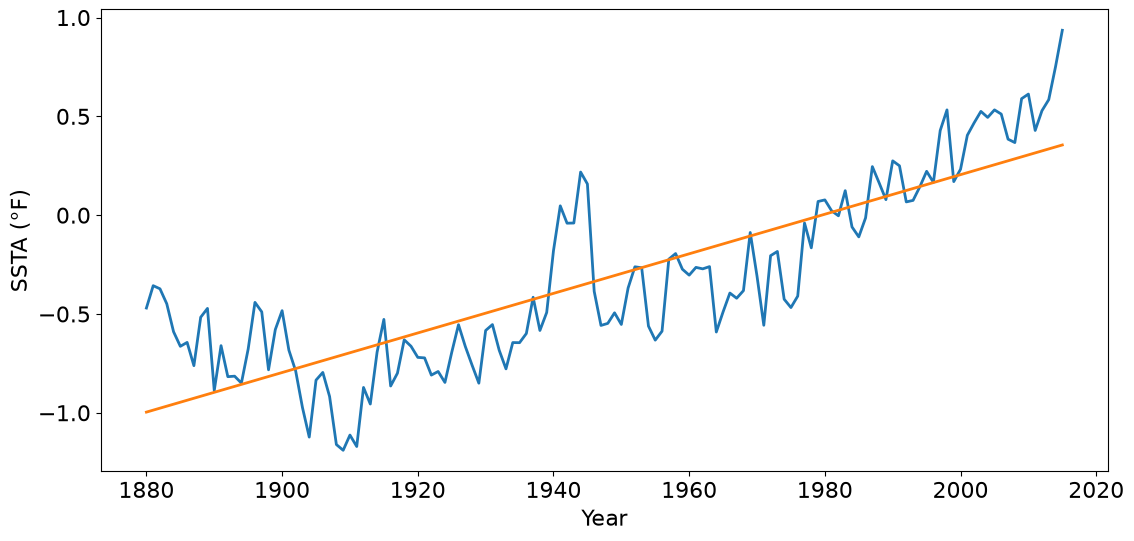

In [42]:
plt.plot(sst_ds.Year, sst_ds["Annual anomaly"])

# plot the line
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept)

plt.xlabel('Year')
plt.ylabel('SSTA ($\degree$F)')

How good of a fit is this for the last few decades?
It's not so good, the trend is bigger, steeper

#### Let's do a linear fit for the last few decades and see what we get.

How do we access the later data?

In [43]:
sst_ds.Year[100:]

<xarray.DataArray 'Year' (Year: 36)> Size: 288B
[36 values with dtype=int64]
Coordinates:
  * Year     (Year) int64 288B 1980 1981 1982 1983 1984 ... 2012 2013 2014 2015

In [44]:
sst_ds["Annual anomaly"][100:]

<xarray.DataArray 'Annual anomaly' (Year: 36)> Size: 288B
array([ 0.0771966,  0.0219924, -0.0032202,  0.1239354, -0.0596304,
       -0.109917 , -0.0137916,  0.2456388,  0.1634436,  0.0785898,
        0.274842 ,  0.2497932,  0.0669942,  0.0748224,  0.1436454,
        0.2219328,  0.1661922,  0.428193 ,  0.5327244,  0.1698606,
        0.2325024,  0.4042188,  0.4671414,  0.5250798,  0.4946364,
        0.5327874,  0.5114556,  0.3846042,  0.3673116,  0.5894424,
        0.6127182,  0.4286736,  0.528696 ,  0.5846742,  0.7512552,
        0.935577 ])
Coordinates:
  * Year     (Year) int64 288B 1980 1981 1982 1983 1984 ... 2012 2013 2014 2015

In [45]:
# the syntax for this function is x,y, so time, ssta
ssta_trend_1980_on = stats.linregress(sst_ds.Year[100:], sst_ds["Annual anomaly"][100:])

In [46]:
ssta_trend_1980_on

LinregressResult(slope=np.float64(0.020711260308880312), intercept=np.float64(-41.05951991698843), rvalue=np.float64(0.8829830021529422), pvalue=np.float64(1.0383113887943913e-12), stderr=np.float64(0.0018882626420977902), intercept_stderr=np.float64(3.7718556347573653))

In [47]:
ssta_trend_1980_on.slope # 0.02 F/ year. 0.2 F /10 years

np.float64(0.020711260308880312)

Text(0, 0.5, 'SSTA ($\\degree$F)')

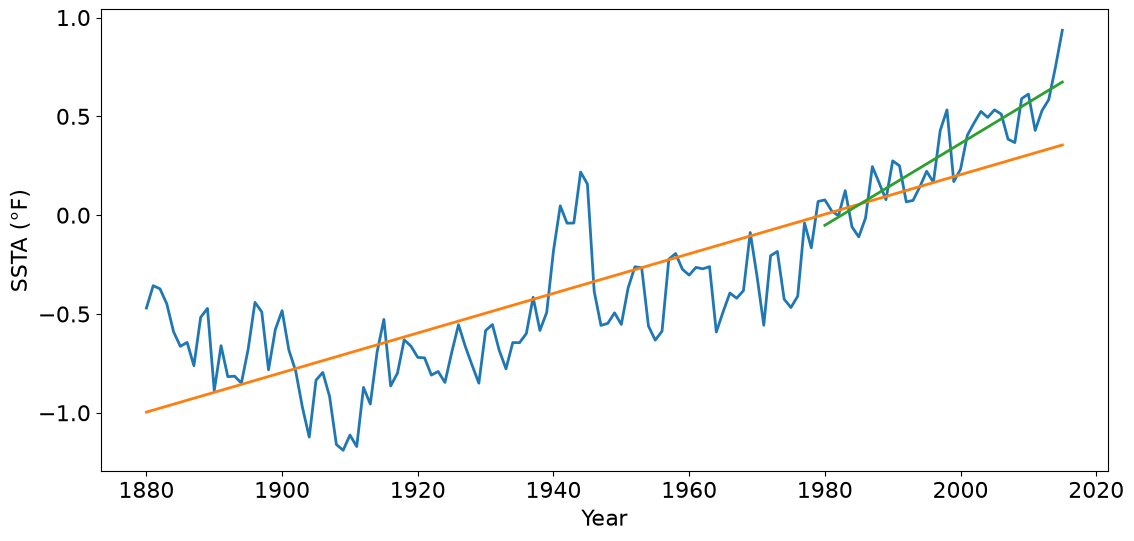

In [48]:
plt.plot(sst_ds.Year, sst_ds["Annual anomaly"])
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept)
plt.plot(sst_ds.Year[100:], ssta_trend_1980_on.slope*sst_ds.Year[100:] + ssta_trend_1980_on.intercept)
plt.xlabel('Year')
plt.ylabel('SSTA ($\degree$F)')

#### Detrending the data
Let's say we were interested in the variability outside of the trend. How do we detrend the data?

In [49]:
# First I am going to make the line, as I plotted before
trend_entire = ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept


In [50]:
trend_entire


<xarray.DataArray 'Year' (Year: 136)> Size: 1kB
array([-0.99664904, -0.98663553, -0.97662203, -0.96660853, -0.95659502,
       -0.94658152, -0.93656802, -0.92655451, -0.91654101, -0.90652751,
       -0.896514  , -0.8865005 , -0.876487  , -0.86647349, -0.85645999,
       -0.84644649, -0.83643298, -0.82641948, -0.81640598, -0.80639247,
       -0.79637897, -0.78636547, -0.77635196, -0.76633846, -0.75632496,
       -0.74631146, -0.73629795, -0.72628445, -0.71627095, -0.70625744,
       -0.69624394, -0.68623044, -0.67621693, -0.66620343, -0.65618993,
       -0.64617642, -0.63616292, -0.62614942, -0.61613591, -0.60612241,
       -0.59610891, -0.5860954 , -0.5760819 , -0.5660684 , -0.55605489,
       -0.54604139, -0.53602789, -0.52601438, -0.51600088, -0.50598738,
       -0.49597387, -0.48596037, -0.47594687, -0.46593336, -0.45591986,
       -0.44590636, -0.43589285, -0.42587935, -0.41586585, -0.40585234,
       -0.39583884, -0.38582534, -0.37581183, -0.36579833, -0.35578483,
       -0.34577132, -0.33575782, -0.32574432, -0.31573081, -0.30571731,
       -0.29570381, -0.2856903 , -0.2756768 , -0.2656633 , -0.25564979,
       -0.24563629, -0.23562279, -0.22560929, -0.21559578, -0.20558228,
       -0.19556878, -0.18555527, -0.17554177, -0.16552827, -0.15551476,
       -0.14550126, -0.13548776, -0.12547425, -0.11546075, -0.10544725,
       -0.09543374, -0.08542024, -0.07540674, -0.06539323, -0.05537973,
       -0.04536623, -0.03535272, -0.02533922, -0.01532572, -0.00531221,
        0.00470129,  0.01471479,  0.0247283 ,  0.0347418 ,  0.0447553 ,
        0.05476881,  0.06478231,  0.07479581,  0.08480932,  0.09482282,
        0.10483632,  0.11484983,  0.12486333,  0.13487683,  0.14489034,
        0.15490384,  0.16491734,  0.17493085,  0.18494435,  0.19495785,
        0.20497136,  0.21498486,  0.22499836,  0.23501187,  0.24502537,
        0.25503887,  0.26505237,  0.27506588,  0.28507938,  0.29509288,
        0.30510639,  0.31511989,  0.32513339,  0.3351469 ,  0.3451604 ,
        0.3551739 ])
Coordinates:
  * Year     (Year) int64 1kB 1880 1881 1882 1883 1884 ... 2012 2013 2014 2015

In [51]:
# Then I will subtract the trend, the line
sst_detrended = sst_ds["Annual anomaly"] - trend_entire

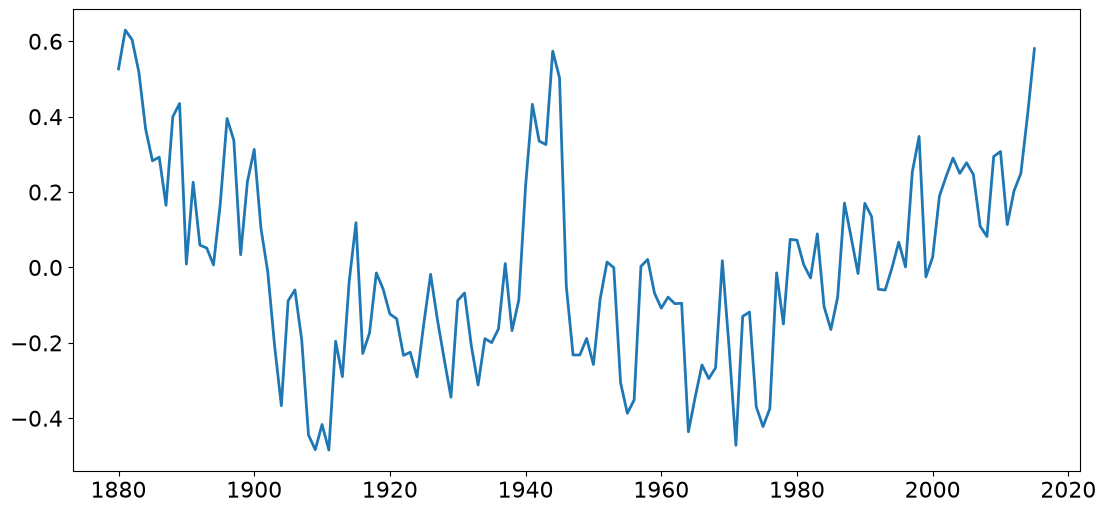

In [52]:
plt.plot(sst_ds.Year, sst_detrended)

#### Creating a moving average, i.e. filtering or smoothing.
Let's say we wanted to smooth the data to remove some of the variability, how would we do this?

I want to do a three year running mean, so for each datapoint, average the year before, the current year and the year after and save that to the current year as the new data.

if i is my current year index

(data[j+1] + data [j] + data [j-1])/3 to average the three years of data

Going to have to start at the second year, since I don't have a previous year


pseudo code:

create an array to save the new data in

Loop through all the years
 take a mean of the current, previous and next years, save to some new arrray


In [53]:
import numpy as np

In [54]:
sst_ds["Annual anomaly"].shape

(136,)

In [55]:
# initialize my array
ssta_filtered = np.zeros(136)

In [56]:
for i in range(134): # loop through all the years, skip the last index
    #print(i+1) #skip the first index
    ssta_filtered[i+1] = (sst_ds["Annual anomaly"][i] + sst_ds["Annual anomaly"][i+1] + sst_ds["Annual anomaly"][i+2])/3


In [57]:
ssta_filtered

array([ 0.       , -0.3998496, -0.392661 , -0.470286 , -0.5672838,
       -0.6324492, -0.689739 , -0.6407322, -0.58335  , -0.6253368,
       -0.6732342, -0.7884066, -0.7641546, -0.8273058, -0.7806204,
       -0.656106 , -0.5359902, -0.571089 , -0.6169062, -0.6148638,
       -0.5817162, -0.6515784, -0.8148972, -0.9615408, -0.9770328,
       -0.9178932, -0.8494422, -0.958077 , -1.089387 , -1.154415 ,
       -1.1577162, -1.0517418, -0.9994074, -0.8402694, -0.7254816,
       -0.6950514, -0.7305318, -0.7649316, -0.697887 , -0.6712272,
       -0.7017474, -0.7504014, -0.7741902, -0.8156208, -0.7774104,
       -0.6984828, -0.6376662, -0.6591012, -0.7577646, -0.730929 ,
       -0.6625068, -0.6069534, -0.671682 , -0.7020222, -0.689259 ,
       -0.6296118, -0.5532168, -0.5326164, -0.4971444, -0.4185516,
       -0.2083398, -0.0577464, -0.0110928,  0.045882 ,  0.1120092,
       -0.0031734, -0.2618532, -0.4970154, -0.5332902, -0.5316978,
       -0.4719516, -0.3943236, -0.2986428, -0.3629202, -0.4866

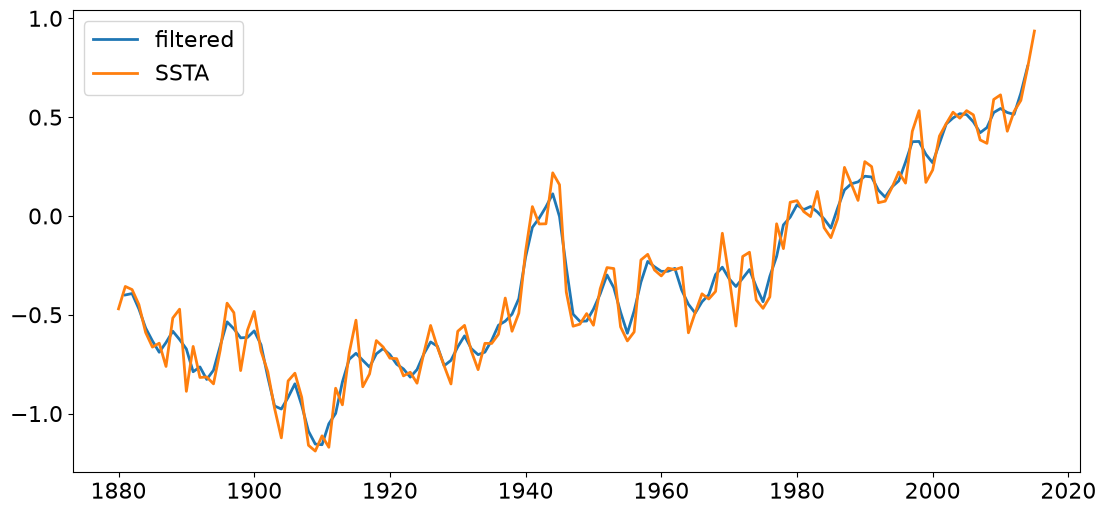

In [58]:
plt.plot(sst_ds.Year[1:-1],ssta_filtered[1:-1], label = "filtered")
plt.plot(sst_ds.Year,sst_ds["Annual anomaly"], label = 'SSTA')
plt.legend()

# Lab 12.1

**E.1** Define a datetime object that is your birthday. Increment this date using timedelta by a) ten weeks, b) five minutes, c) two years (tricky!) Hint: see help(timedelta)

In [59]:
my_bday = datetime(2004, 1, 26)
print(my_bday)

# a) ten weeks
print(my_bday + timedelta(weeks=10))

# b) five minutes
print(my_bday + timedelta(minutes=5))

# c) two years - timedelta doesn't have a years option, so I used days
print(my_bday + timedelta(days=365*2))
# ^ this gives Jan 25 instead of Jan 26 because 2004 was a leap year (Feb 29 is in between)

# found relativedelta online, it adds actual calendar years
from dateutil.relativedelta import relativedelta
print(my_bday + relativedelta(years=2))

2004-01-26 00:00:00
2004-04-05 00:00:00
2004-01-26 00:05:00
2006-01-25 00:00:00
2006-01-26 00:00:00


**E.2** Define a daterange for your birthday every year of your life

In [60]:
# freq='YE' gives Dec 31 of every year, so I used DateOffset to go one year at a time from my birthday
my_birthdays = pd.date_range(start=my_bday, end=datetime.today(), freq=pd.DateOffset(years=1))
my_birthdays

DatetimeIndex(['2004-01-26', '2005-01-26', '2006-01-26', '2007-01-26',
               '2008-01-26', '2009-01-26', '2010-01-26', '2011-01-26',
               '2012-01-26', '2013-01-26', '2014-01-26', '2015-01-26',
               '2016-01-26', '2017-01-26', '2018-01-26', '2019-01-26',
               '2020-01-26', '2021-01-26', '2022-01-26', '2023-01-26',
               '2024-01-26', '2025-01-26', '2026-01-26'],
              dtype='datetime64[us]', freq='<DateOffset: years=1>')

**E.3** Print all your birthdays out as month, day, year (no minutes, etc)

In [61]:
for day in my_birthdays:
    print(day.strftime('%m/%d/%Y'))

01/26/2004
01/26/2005
01/26/2006
01/26/2007
01/26/2008
01/26/2009
01/26/2010
01/26/2011
01/26/2012
01/26/2013
01/26/2014
01/26/2015
01/26/2016
01/26/2017
01/26/2018
01/26/2019
01/26/2020
01/26/2021
01/26/2022
01/26/2023
01/26/2024
01/26/2025
01/26/2026


**E.4** Do a linear fit of the SSTA data from 1940 to 1970. What trend do you get? How confident are you in this result? How does it compare to the trends we did in lecture (use quantitative data to explain).

In [62]:
# 1880 is index 0, so 1940 is index 60 and 1970 is index 90
print(sst_ds.Year[60].values, sst_ds.Year[90].values)

ssta_trend_1940_1970 = stats.linregress(sst_ds.Year[60:91], sst_ds["Annual anomaly"][60:91])
ssta_trend_1940_1970

1940 1970


LinregressResult(slope=np.float64(-0.008184913548387096), intercept=np.float64(15.69453642580645), rvalue=np.float64(-0.336258115900317), pvalue=np.float64(0.0643797087189174), stderr=np.float64(0.004256837897140221), intercept_stderr=np.float64(8.32220518488094))

In [63]:
# compare with the trends from lecture
print(f'1880-2015: slope = {ssta_trend_entire.slope:.4f} +/- {ssta_trend_entire.stderr:.4f} F/yr, '
      f'r^2 = {ssta_trend_entire.rvalue**2:.2f}, p = {ssta_trend_entire.pvalue:.2g}')
print(f'1980-2015: slope = {ssta_trend_1980_on.slope:.4f} +/- {ssta_trend_1980_on.stderr:.4f} F/yr, '
      f'r^2 = {ssta_trend_1980_on.rvalue**2:.2f}, p = {ssta_trend_1980_on.pvalue:.2g}')
print(f'1940-1970: slope = {ssta_trend_1940_1970.slope:.4f} +/- {ssta_trend_1940_1970.stderr:.4f} F/yr, '
      f'r^2 = {ssta_trend_1940_1970.rvalue**2:.2f}, p = {ssta_trend_1940_1970.pvalue:.2g}')

1880-2015: slope = 0.0100 +/- 0.0006 F/yr, r^2 = 0.70, p = 8.8e-37
1980-2015: slope = 0.0207 +/- 0.0019 F/yr, r^2 = 0.78, p = 1e-12
1940-1970: slope = -0.0082 +/- 0.0043 F/yr, r^2 = 0.11, p = 0.064


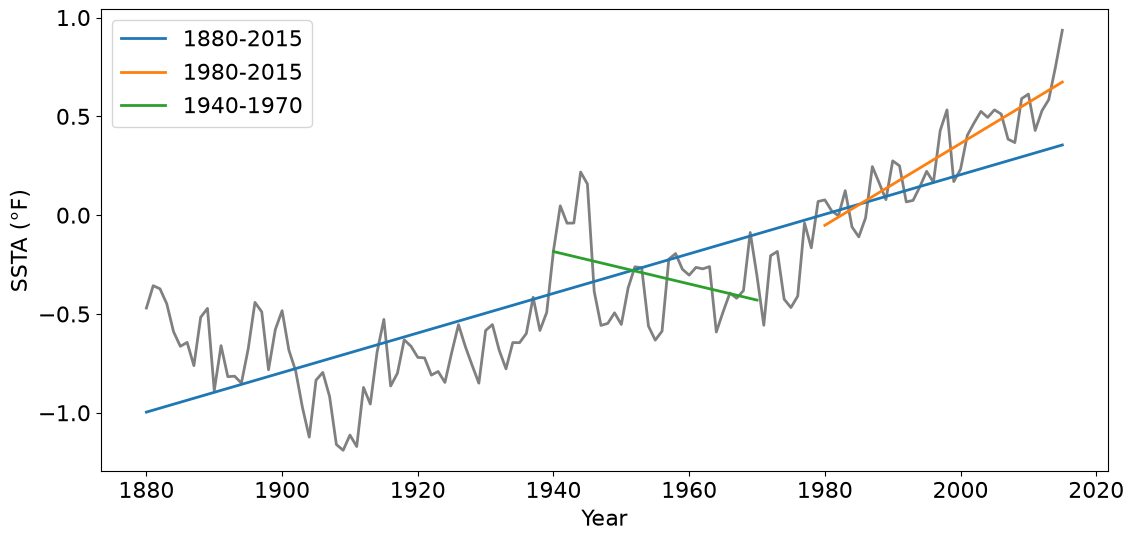

In [64]:
plt.plot(sst_ds.Year, sst_ds["Annual anomaly"], color='gray')
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept, label='1880-2015')
plt.plot(sst_ds.Year[100:], ssta_trend_1980_on.slope*sst_ds.Year[100:] + ssta_trend_1980_on.intercept, label='1980-2015')
plt.plot(sst_ds.Year[60:91], ssta_trend_1940_1970.slope*sst_ds.Year[60:91] + ssta_trend_1940_1970.intercept, label='1940-1970')
plt.xlabel('Year')
plt.ylabel(r'SSTA ($\degree$F)')
plt.legend()

The trend from 1940 to 1970 is about -0.008 °F/year (about -0.08 °F per decade), so SST actually went down a little during this time.

I'm not very confident in this result though. The standard error is 0.0043, so the 95% confidence interval (about 2 standard errors) is roughly -0.008 ± 0.009, which includes zero. The p-value is 0.064, which is above 0.05, so the trend isn't statistically significant. r² is only 0.11, so the line doesn't explain much of the variability. The result also depends a lot on the start year: 1940 is right at the start of the warm bump in the early 1940s, and then there's a big drop in 1946.

Compared to the lecture trends, the whole record (1880-2015) has a slope of +0.010 °F/year (r² = 0.70), and 1980-2015 has +0.021 °F/year (r² = 0.78). Both have p-values way below 0.05 (around 10⁻³⁷ and 10⁻¹²), and their standard errors are much smaller (0.0006 and 0.0019, compared to 0.0043). So the 1940-1970 trend has the opposite sign and is much less certain. It looks more like a short pause in the long-term warming than a real reversal.

**E.5** According to the internet, what might have caused this decline in SST during this perioud? Write a few sentances explaining this and cite your sources here.

From what I found, there are two main reasons.

The first is aerosol pollution. After WWII, industry grew a lot and burned coal and oil without much pollution control, which put sulfate aerosols into the atmosphere. These particles reflect sunlight back to space, so they have a cooling effect that canceled out some of the warming from CO2 at the time (Brahic, 2007). The amount of sunlight reaching the surface went down at a lot of places between the 1950s and 1980s, which is called "global dimming" (Wild, 2009). The 1963 Mount Agung eruption also added volcanic aerosols, and solar activity leveled off around then (Brahic, 2007). Once clean air laws in Europe and North America cut down sulfate emissions, the greenhouse warming took over again, which is why temperatures go up fast after 1970 (Brahic, 2007).

The second reason is partly a measurement problem. Most SST measurements back then came from ships. During WWII most of the data came from US ships that measured water temperature at the engine intake, which reads warm. After 1945 most of it came from British ships that used buckets, which read cool because of evaporation. This switch made global SST look like it dropped about 0.3 °C in 1945 (Thompson et al., 2008). ERSST v4 (the dataset we're using) does adjust for ship measurement biases (Huang et al., 2015), but you can still see the big drop from 1945 (+0.16 °F) to 1946 (-0.39 °F) in our data. So the real cooling was probably smaller and more gradual than it looks here.

Sources:
- Brahic, C. (2007, May 16). Climate myths: The cooling after 1940 shows CO2 does not cause warming. *New Scientist*. https://www.newscientist.com/article/dn11639-climate-myths-the-cooling-after-1940-shows-co2-does-not-cause-warming/
- Thompson, D. W. J., Kennedy, J. J., Wallace, J. M., & Jones, P. D. (2008). A large discontinuity in the mid-twentieth century in observed global-mean surface temperature. *Nature*, 453, 646-649. https://doi.org/10.1038/nature06982
- Wild, M. (2009). Global dimming and brightening: A review. *Journal of Geophysical Research*, 114, D00D16. https://doi.org/10.1029/2008JD011470
- Huang, B., et al. (2015). Extended Reconstructed Sea Surface Temperature version 4 (ERSST.v4). Part I: Upgrades and intercomparisons. *Journal of Climate*, 28(3), 911-930. https://doi.org/10.1175/JCLI-D-14-00006.1

**E.6** Detrend from 1970 on and plot your result. Compare this to an ENSO (El Nino) index and speculate on what may have caused this interannual variability. How does ENSO affect SST and why?

1970-2015 trend: 0.0231983908973173


Text(0.5, 1.0, 'SSTA from 1970 on with the trend removed')

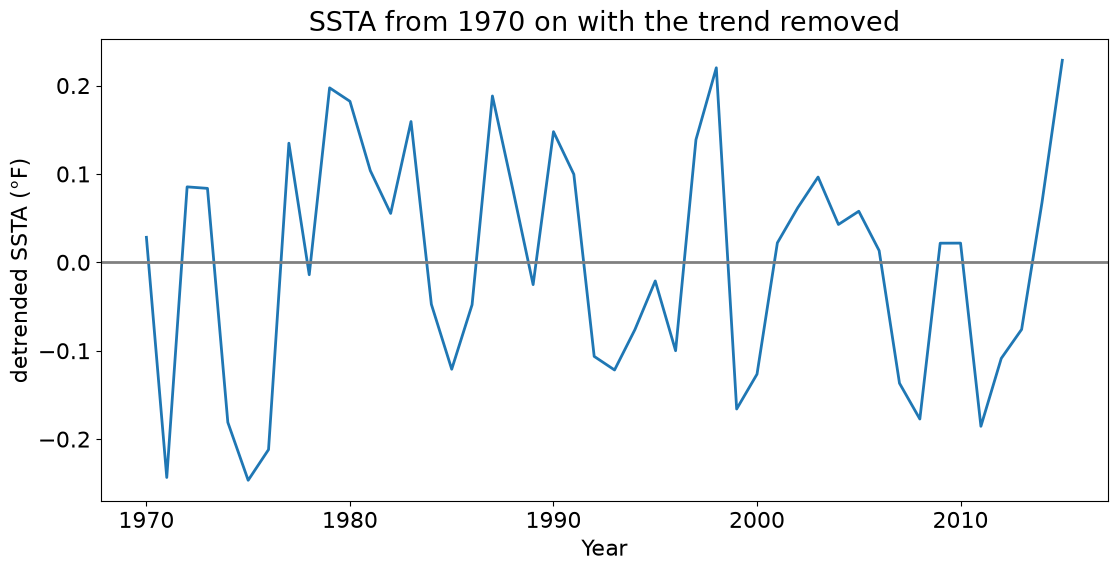

In [65]:
# detrend from 1970 on (index 90 is 1970), same steps as lecture
ssta_trend_1970_on = stats.linregress(sst_ds.Year[90:], sst_ds["Annual anomaly"][90:])
print('1970-2015 trend:', ssta_trend_1970_on.slope)

trend_1970_on = ssta_trend_1970_on.slope*sst_ds.Year[90:] + ssta_trend_1970_on.intercept
sst_detrended_1970 = sst_ds["Annual anomaly"][90:] - trend_1970_on

plt.plot(sst_ds.Year[90:], sst_detrended_1970)
plt.axhline(0, color='gray')
plt.xlabel('Year')
plt.ylabel(r'detrended SSTA ($\degree$F)')
plt.title('SSTA from 1970 on with the trend removed')

In [66]:
# ENSO index: Oceanic Nino Index (ONI) from NOAA CPC
# https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/ensostuff/ONI_v5.php
oni = pd.read_csv('https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt', sep=r'\s+')
oni

,SEAS,YR,TOTAL,ANOM
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10
...,...,...,...,...
916,AMJ,2026,28.74,0.95
917,MJJ,2026,29.02,1.39
918,JJA,2026,29.09,1.80
919,JAS,2026,29.12,2.16


correlation: 0.6591298324590729


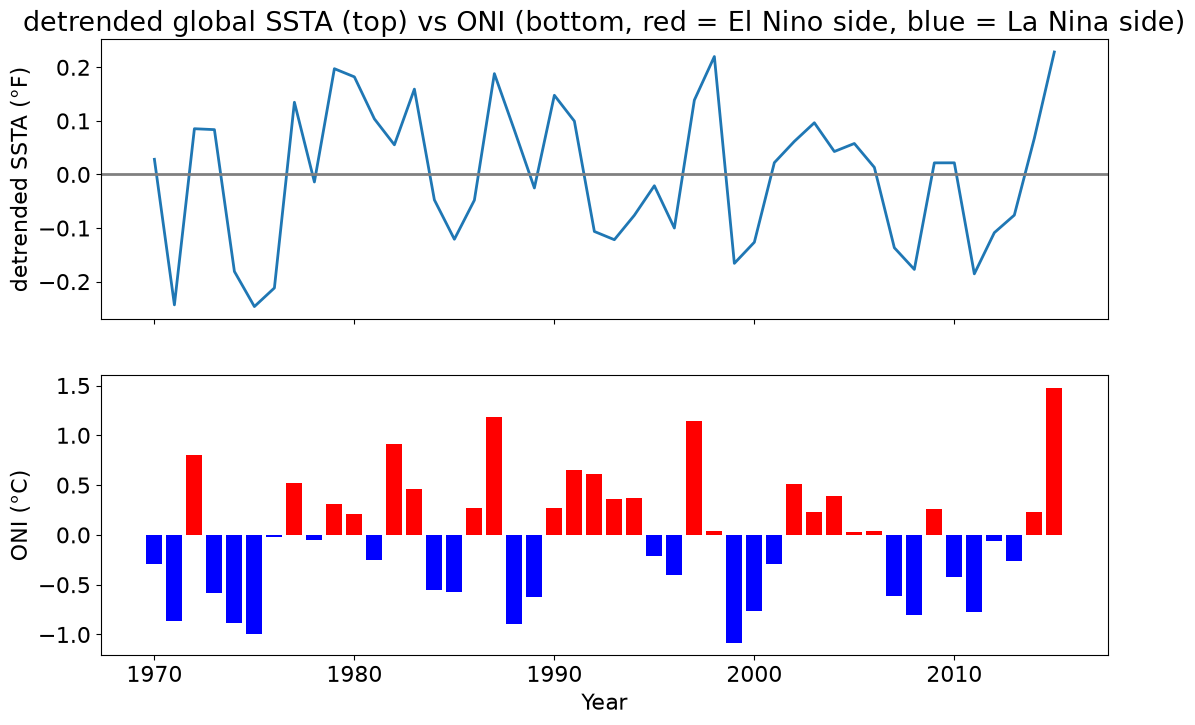

In [67]:
# ONI is a 3-month running mean, so I averaged each year to compare with the annual SST data
oni_annual = oni.groupby('YR')['ANOM'].mean()
oni_annual = oni_annual.loc[1970:2015]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
ax1.plot(sst_ds.Year[90:], sst_detrended_1970)
ax1.axhline(0, color='gray')
ax1.set_ylabel(r'detrended SSTA ($\degree$F)')
ax1.set_title('detrended global SSTA (top) vs ONI (bottom, red = El Nino side, blue = La Nina side)')
ax2.bar(oni_annual.index, oni_annual, color=np.where(oni_annual > 0, 'red', 'blue'))
ax2.set_ylabel(r'ONI ($\degree$C)')
ax2.set_xlabel('Year')

print('correlation:', np.corrcoef(sst_detrended_1970.values, oni_annual.values)[0, 1])

After taking out the trend (about 0.023 °F/year from 1970 on), the leftover year-to-year changes are around ±0.25 °F, and they line up pretty well with ENSO. The correlation between the detrended SSTA and the yearly average ONI is about 0.66. The warmest years (1983, 1987, 1998, 2015) are all strong El Niño years, and the coldest years (1971, 1974-76, 1999-2000, 2008, 2011) are La Niña years. So I think a lot of the interannual variability in global SST comes from ENSO.

Some years don't match, like 1992-1994, which are cool even though there was an El Niño in 1991-92. I think that's probably from the Mount Pinatubo eruption in 1991, since volcanic aerosols block sunlight for a couple of years.

ENSO affects SST because of the trade winds in the tropical Pacific. Normally they blow from east to west. That piles warm water up in the western Pacific and brings cold water up from below (upwelling) in the eastern Pacific near South America.
- During El Niño the trade winds weaken, the warm water spreads back east, and the cold upwelling slows down. A huge part of the tropical Pacific warms up, which raises the global average SST.
- La Niña is the opposite: stronger trade winds, more upwelling, and a colder eastern Pacific, so global SST goes down.

El Niño usually peaks around December, so the global SST peak often shows up in the year after it starts. For example, the 1997-98 El Niño made 1998 the warm year.

**E.7** Perform a five year moving average of your detrended data from E.6. Explain your result in relation to the periodicity of ENSO.

std of detrended SSTA: 0.12928897454336863  after 5 year average: 0.062320842608852046


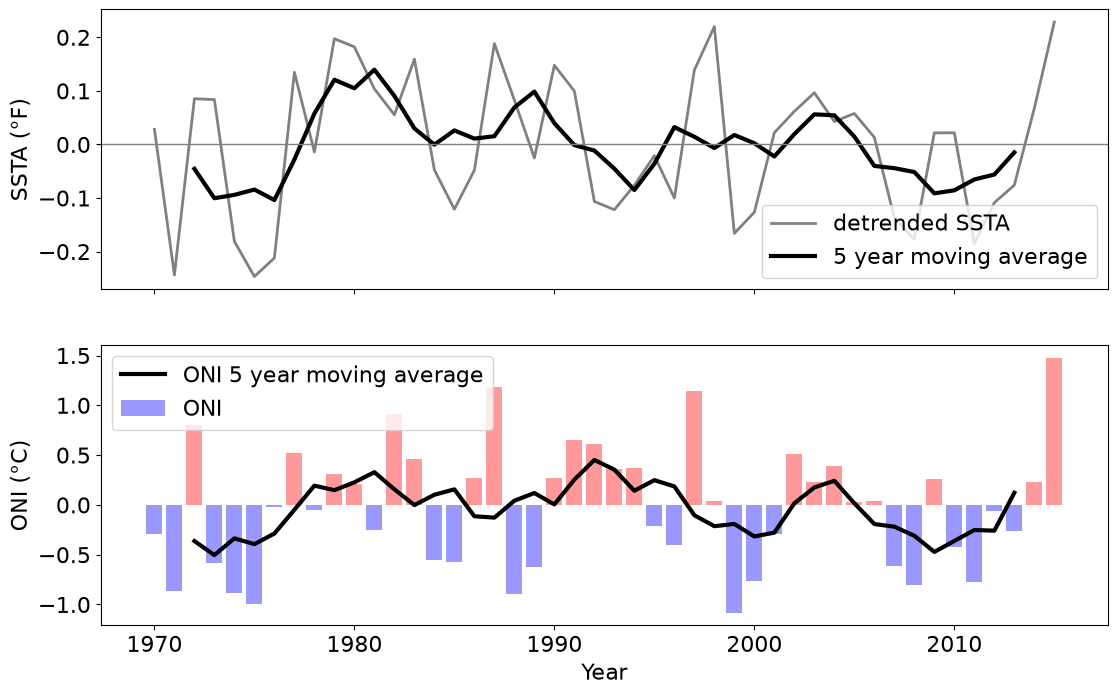

In [68]:
# 5 year moving average, same idea as the 3 year one from lecture but 2 years on each side
ssta_det = sst_detrended_1970.values
n = len(ssta_det)
ssta_5yr = np.full(n, np.nan)   # nan instead of zeros so the ends don't plot as 0

for i in range(2, n-2):
    ssta_5yr[i] = (ssta_det[i-2] + ssta_det[i-1] + ssta_det[i] + ssta_det[i+1] + ssta_det[i+2])/5

# also smooth the ONI the same way to compare (pandas rolling does the same thing)
oni_5yr = oni_annual.rolling(5, center=True).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
ax1.plot(sst_ds.Year[90:], ssta_det, color='gray', label='detrended SSTA')
ax1.plot(sst_ds.Year[90:], ssta_5yr, color='k', linewidth=3, label='5 year moving average')
ax1.axhline(0, color='gray', linewidth=1)
ax1.set_ylabel(r'SSTA ($\degree$F)')
ax1.legend(loc='lower right')

ax2.bar(oni_annual.index, oni_annual, color=np.where(oni_annual > 0, 'red', 'blue'), alpha=0.4, label='ONI')
ax2.plot(oni_5yr.index, oni_5yr, color='k', linewidth=3, label='ONI 5 year moving average')
ax2.set_ylabel(r'ONI ($\degree$C)')
ax2.set_xlabel('Year')
ax2.legend(loc='upper left')

print('std of detrended SSTA:', np.nanstd(ssta_det), ' after 5 year average:', np.nanstd(ssta_5yr))

The 5-year moving average gets rid of most of the year-to-year ups and downs. The standard deviation drops from about 0.13 °F to about 0.06 °F, and the individual El Niño and La Niña spikes (like 1998 and 2008) are mostly gone.

This makes sense because ENSO has a period of about 2-7 years, and El Niño and La Niña tend to alternate. A 5-year window covers about one full ENSO cycle, so each average includes both warm and cold years and they mostly cancel out. You can see the same thing with the ONI in the bottom plot: the 5-year average is a lot flatter than the yearly values.

It doesn't cancel perfectly though, because ENSO isn't perfectly regular. When there are several La Niñas in a row (like 1973-76 or 2007-2012), the 5-year average stays negative. What's left after smoothing is slower, decadal variability:
- the warmer late 1970s and early 1980s
- the dip in the early 1990s (probably Pinatubo again)
- the cooler period around 2006-2012, before the big 2015 El Niño

**Notes** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.